Урок в прозе: https://proproprogs.ru/nn_pytorch/pytorch-algoritm-batch-normalization  
neuro_net_25_bm.py: https://github.com/selfedu-rus/neuro-pytorch

Батч-нормализация приводит распределение значений нейронов внутри батча к N(0, 1). То есть грубо говоря у нас батч из 32 сэмплов, на слое 7 нейронов, тогда каждый нейрон в батче представлен распределением из 32 значений

Считается, что батс-норм работаюь на более фундаментальном уровне, чем дропаут, и больше способствует развитию обобщающей способности модели. Не рекомендуется на одном слое использовать оба меода, так как дропаут отключает некоторые нейроны и тем самым искажает статистику

На том слое, к которому применяется батч-нормализация, следует отключать bias

 | loss_mean=0.258, Q_val=0.168


 | loss_mean=0.156, Q_val=0.185


 | loss_mean=0.124, Q_val=0.473


 | loss_mean=0.107, Q_val=0.275


 | loss_mean=0.097, Q_val=0.138


 | loss_mean=0.089, Q_val=0.155


... (10 outputs left out)

 | loss_mean=0.045, Q_val=0.150


 | loss_mean=0.045, Q_val=0.140


 | loss_mean=0.043, Q_val=0.157


 | loss_mean=0.043, Q_val=0.143
0.975


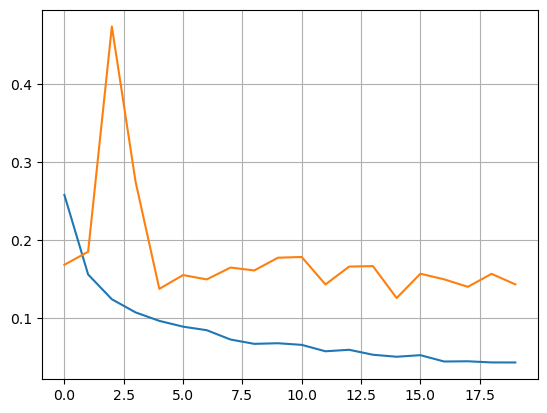

In [1]:
import matplotlib.pyplot as plt

import torch
import torch.utils.data as data
import torchvision.transforms.v2 as tfs
import torchvision
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm
from torchvision.datasets import ImageFolder


class RavelTransform(nn.Module):
    def forward(self, item):
        return item.ravel()


class DigitNN(nn.Module):
    def __init__(self, input_dim, num_hidden, output_dim):
        super().__init__()
        self.layer1 = nn.Linear(input_dim, num_hidden, bias=False)
        self.layer2 = nn.Linear(num_hidden, output_dim)
        self.bm_1 = nn.BatchNorm1d(num_hidden)

    def forward(self, x):
        x = self.layer1(x)
        x = nn.functional.relu(x)
        x = self.bm_1(x)
        x = self.layer2(x)
        return x


model = DigitNN(28 * 28, 128, 10)

transforms = tfs.Compose([tfs.ToImage(),  tfs.Grayscale(),
                          tfs.ToDtype(torch.float32, scale=True),
                          RavelTransform(),
                          ])

dataset_mnist = torchvision.datasets.MNIST(r'C:\datasets\mnist', download=True, train=True, transform=transforms)
d_train, d_val = data.random_split(dataset_mnist, [0.7, 0.3])
train_data = data.DataLoader(d_train, batch_size=32, shuffle=True)
train_data_val = data.DataLoader(d_val, batch_size=32, shuffle=False)


optimizer = optim.Adam(params=model.parameters(), lr=0.01) # , weight_decay=0.001)
loss_function = nn.CrossEntropyLoss()
epochs = 20

loss_lst_val = [] # список значений потерь при валидации
loss_lst = [] # список значений потерь при обучении

for _e in range(epochs):
    model.train()
    loss_mean = 0
    lm_count = 0

    train_tqdm = tqdm(train_data, leave=False)
    for x_train, y_train in train_tqdm:
        predict = model(x_train)
        loss = loss_function(predict, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        lm_count += 1
        loss_mean = 1/lm_count * loss.item() + (1 - 1/lm_count) * loss_mean
        train_tqdm.set_description(f"Epoch [{_e+1}/{epochs}], loss_mean={loss_mean:.3f}")

    # валидация модели
    model.eval()
    Q_val = 0
    count_val = 0

    for x_val, y_val in train_data_val:
        with torch.no_grad():
            p = model(x_val)
            loss = loss_function(p, y_val)
            Q_val += loss.item()
            count_val += 1

    Q_val /= count_val

    loss_lst.append(loss_mean)
    loss_lst_val.append(Q_val)

    print(f" | loss_mean={loss_mean:.3f}, Q_val={Q_val:.3f}")

d_test = torchvision.datasets.MNIST(r'C:\datasets\mnist', download=True, train=False, transform=transforms)
test_data = data.DataLoader(d_test, batch_size=500, shuffle=False)

Q = 0

# тестирование обученной НС
model.eval()

for x_test, y_test in test_data:
    with torch.no_grad():
        p = model(x_test)
        p = torch.argmax(p, dim=1)
        Q += torch.sum(p == y_test).item()

Q /= len(d_test)
print(Q)

# вывод графиков
plt.plot(loss_lst)
plt.plot(loss_lst_val)
plt.grid()
plt.show()